# Diamondback Evolutionary Model Interpolation

In this notebook we will demonstrate a simple python class to interpolate the Sonora Diamondback Evolutionary model grid. (Morley 2024: https://doi.org/10.3847/1538-4357/ad71d5). The class is defined inside the file `diamondback_interpolator.py` and we will import it.

In [37]:
from diamondback_interpolator import DiamondbackEvolution

import numpy as np
import matplotlib.pyplot as plt

The class has nine different possible input states, depending on the cloud prescription and metallicity of the grid, which are copied below for reference. Future work could improve this by enabling interpolation along the metallicity dimesion, although you could do this by hand by making multiple classes and interpolating their outputs.

In [38]:
#d1 = DiamondbackEvolution(clouds='nc',mh=-0.5)
#d2 = DiamondbackEvolution(clouds='nc',mh=0)
#d3 = DiamondbackEvolution(clouds='nc',mh=0.5)
#d4 = DiamondbackEvolution(clouds='hybrid',mh=-0.5)
#d5 = DiamondbackEvolution(clouds='hybrid',mh=0.)
#d6 = DiamondbackEvolution(clouds='hybrid',mh=0.5)
#d7 = DiamondbackEvolution(clouds='hybrid-grav',mh=-0.5)
#d8 = DiamondbackEvolution(clouds='hybrid-grav',mh=0.)
#d9 = DiamondbackEvolution(clouds='hybrid-grav',mh=0.5)

For the tutorial we will load one model with no clouds and solar metallicity. Instantiating the class will automatically download the data from Zenodo, and parse the data into an easy to work with format. This will create three folders in the working directory to save the original data `source`, the pickled pandas DataFrames `pkl`, and the output-sliced dictionaries used to interpolate each output axis `interpDict`.

In [40]:
dbe = DiamondbackEvolution(clouds='nc',mh=0)

https://zenodo.org/records/12735103
Evolution tables include each of the three metallicities (0.0, +0.5, -0.5) and come in three versions.
    "nc" denotes cloud-free models for the full evolution.
    "hybrid" includes clouds (fsed=2) above 1300 K and cloud-free below 1300 K (using the Sonora Bobcat models for T<900 K).
    "hybrid-grav" includes clouds (fsed=2) that clear between 1000 and 1300 K, with clouds in lower gravity models persisting to colder tempearatures, again using the Sonora Bobcat models for T<900 K.
downloading models...
done.

loading: self.df = pd.read_pickle(/user/amadurowicz/epsilon/pkl/nc_m0.0_mass.pkl)


The entire grid is saved as a Pandas DataFrame in the `df` attribute which enables easy slicing of the grid

In [49]:
dbe.df

,M/MSun,age(Gyr),log L/Lsun,Teff(K),log g,R/Rjup
0,0.0005,0.0020,-5.6812,536.28,2.688,1.632
1,0.0005,0.0023,-5.7527,519.35,2.704,1.602
2,0.0005,0.0027,-5.8354,500.19,2.722,1.570
3,0.0005,0.0031,-5.9055,484.34,2.736,1.545
4,0.0005,0.0036,-5.9818,467.46,2.750,1.519
...,...,...,...,...,...,...
2954,0.0800,7.2000,-3.6206,2274.18,5.342,0.972
2955,0.0800,8.3000,-3.6206,2274.18,5.342,0.972
2956,0.0800,9.7000,-3.6207,2274.18,5.342,0.972
2957,0.0800,11.0000,-3.6207,2274.18,5.342,0.972


One particular example which is important is the vector of masses

In [50]:
dbe.masses

array([0.0005, 0.001 , 0.0015, 0.002 , 0.0025, 0.003 , 0.0035, 0.004 ,
       0.0045, 0.005 , 0.006 , 0.007 , 0.008 , 0.009 , 0.01  , 0.011 ,
       0.0115, 0.012 , 0.0125, 0.013 , 0.0135, 0.014 , 0.0145, 0.015 ,
       0.0155, 0.016 , 0.0165, 0.017 , 0.0175, 0.018 , 0.0185, 0.019 ,
       0.0195, 0.02  , 0.022 , 0.024 , 0.026 , 0.028 , 0.03  , 0.033 ,
       0.035 , 0.038 , 0.04  , 0.043 , 0.045 , 0.048 , 0.05  , 0.053 ,
       0.055 , 0.058 , 0.06  , 0.063 , 0.064 , 0.065 , 0.066 , 0.067 ,
       0.068 , 0.069 , 0.07  , 0.071 , 0.072 , 0.073 , 0.074 , 0.075 ,
       0.077 , 0.078 , 0.08  ])

This is iterated over to generate classic line plots such as the following example


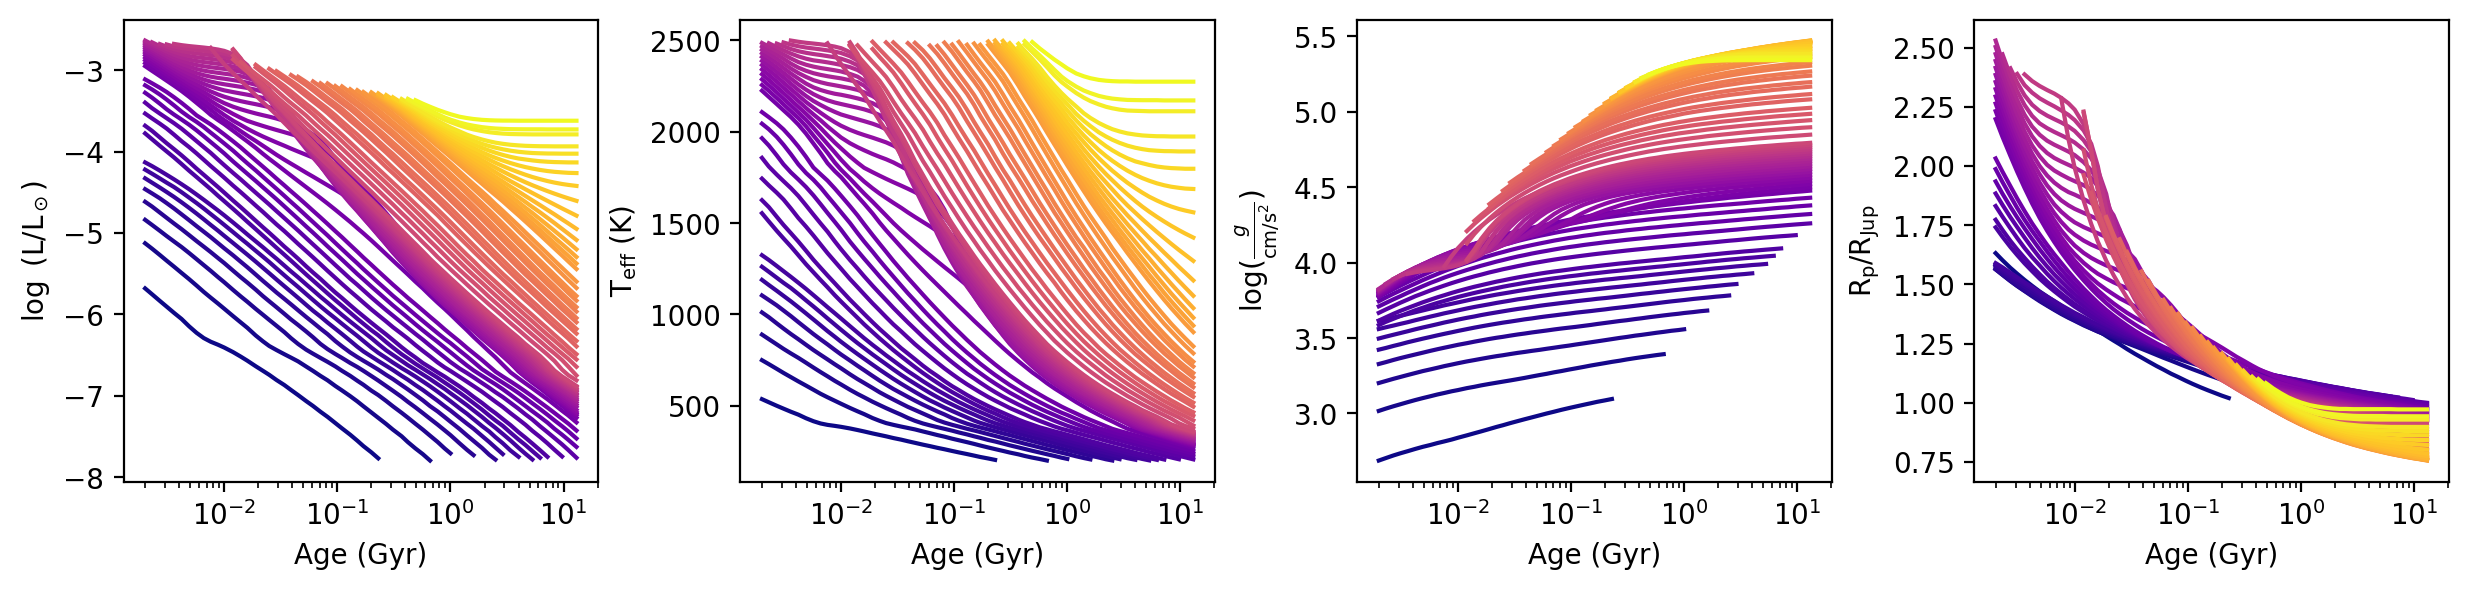

In [51]:
dbe.line_plot()

The code also used this slicing to generate interpolator functions using `scipy.interpolate.griddata` which take in `age (Gyr)` and `mass (Msun)` and output the four resulting parameters `log L/Lsun`, `Teff (K)`, `log g`, `R/Rjup`.

In [54]:
# Age (Gyr) Mass/Msun -> log L/Lsun, Teff (K), log g, R/Rjup
dbe.interpolate((1,.01))

(array(-6.2432), array(480.2), array(4.359), array(1.065))

These are used in an alternate visualization which plots the outputs as a 2D surface over some user defined input.

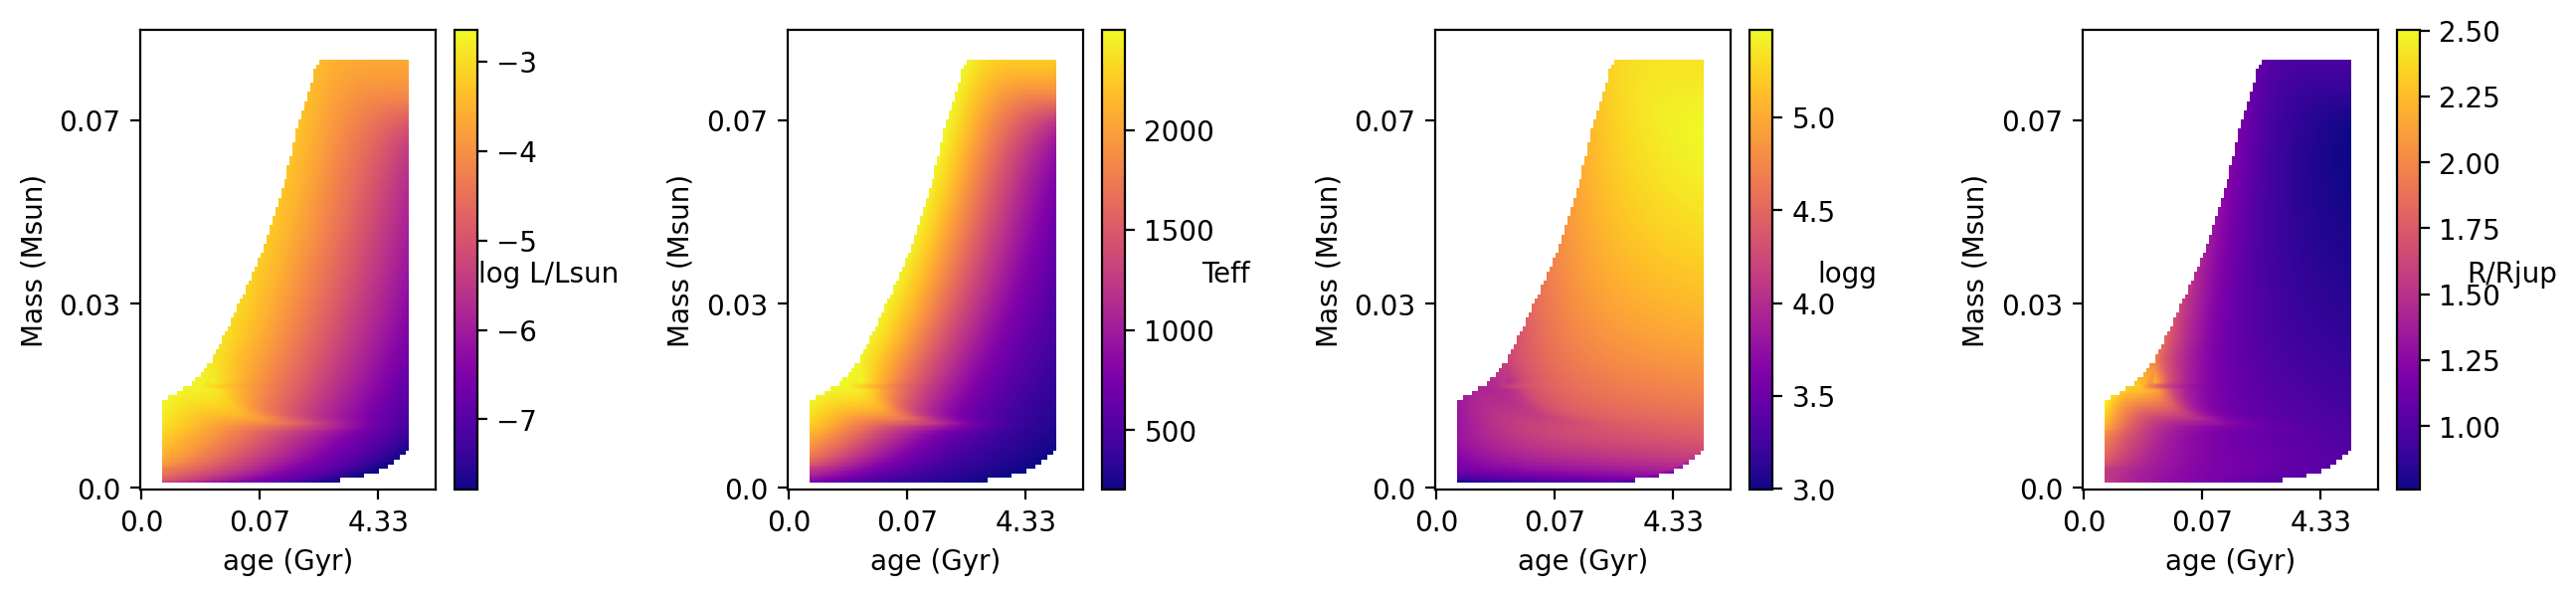

In [55]:
ages, masses = np.logspace(-3,1.5,100), np.linspace(.0001,.085,100)

dbe.interp_plot(ages,masses)

But the primary purpose of the code is not to generate these visualizations, but to evaluate the model on some user defined prior. For this example we will generate gaussian distributions consistent with literature data for 51 Eri b and use the functions `calc_prior`, `prior_plot`, and `prior_print_summary` to transform the age and mass into their correspoding output distributions. All that happes under the hood is repeated evaluation of the `interpolate` function using the pandas slicing.

In [56]:
Mjup = 1.898e27 #kg
Msun = 1.988e30 #kg
N = 10000

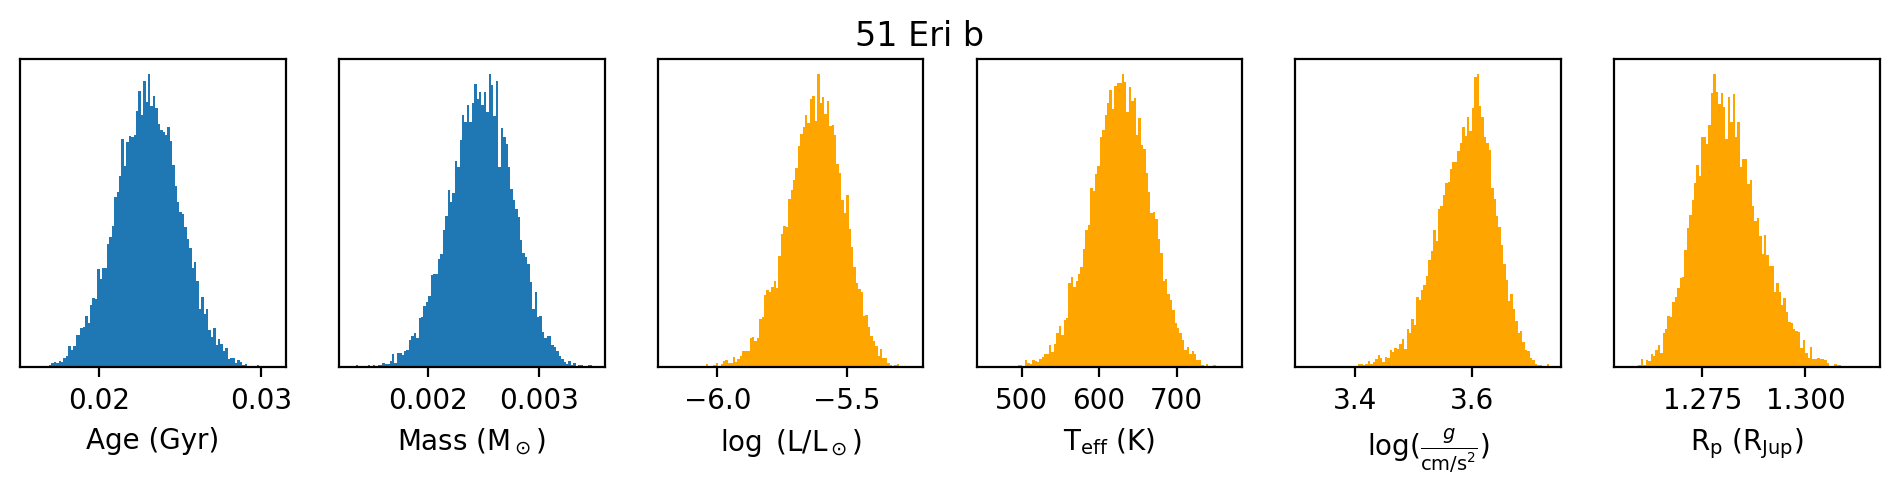

Age (Gyr) = 0.02 +/- 0.0
Mass/Mjup = 2.6 +/- 0.3
log L/Lsun = -5.62 +/- 0.11
Teff (K) = 627.57 +/- 38.08
log g = 3.59 +/- 0.05
R (Rjup) = 1.28 +/- 0.01


In [57]:
name = '51 Eri b'

mass_mu = 2.6*Mjup/Msun
mass_sig = 0.3*Mjup/Msun
mass_prior = mass_mu + mass_sig*np.random.randn(N)

age_mu = 23/1000.
age_sig = 2/1000.
age_prior = age_mu + age_sig*np.random.randn(N)

dbe.calc_prior(age_prior,mass_prior,name)
dbe.prior_plot(name)
dbe.prior_print_summary(name)

There is also the funciton `eval_prior_function` which returns the probabilities over a vector of inputs.

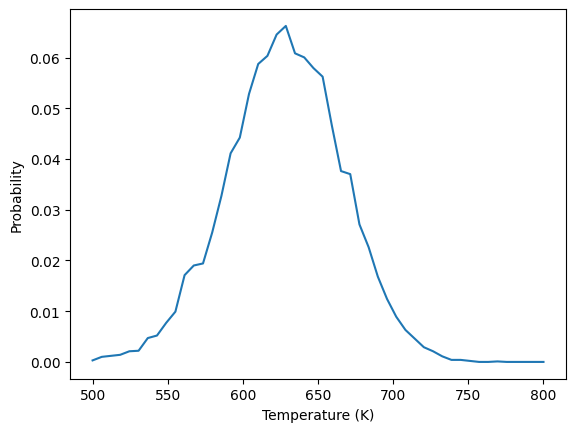

In [58]:
name = '51 Eri b'
prior_index = 3 # 0 = age, 1 = mass, 2 = Luminosity, 3 = Temperature, 4 = log g, 5 = radius
points = np.linspace(500,800) #x coordinate

probability = dbe.eval_prior_function(name, prior_index, points)
assert np.sum(probability) == 1

plt.plot(points,probability)
plt.xlabel('Temperature (K)')
plt.ylabel('Probability')
plt.show()

You can easily define alternate priors such as uniform distributions by changing the inputs.

In [ ]:
name = 'uniform 1-13 Mjup, 1-100 Myr'

mass_prior = np.random.uniform(low=1*Mjup/Msun, high=13*Mjup/Msun, size=N)
age_prior = np.random.uniform(low=1/1000., high=100/1000., size=N)

dbe.calc_prior(age_prior,mass_prior,name)
dbe.prior_plot(name)
dbe.prior_print_summary(name)